# Projeto ArPrev — 03 · Previsão da Próxima Hora (+1h e Projeções)
**ArPrev — Foco na Antecipação de Condições Inadequadas**  
*Mogi das Cruzes / SP — Campus UBC | Trilha B (Qualidade do Ar)*

Terceiro passo do fluxo operacional **+1h a partir de agora**. Este notebook carrega o modelo empacotado (`models/modelo_final_sprint5.joblib`, Random Forest) e responde:

> *Daqui a 1 hora, a qualidade do ar em Mogi das Cruzes estará inadequada (IQAr > 100)?*

A decisão usa o limiar congelado do artefato (0,30): probabilidade **≥ 0,30** gera alerta. O limiar foi calibrado na validação temporal para priorizar sensibilidade (**Recall de 98,14%** no teste cego de 2025–2026, com apenas 3 falsos negativos em quase dois anos).

> **Uso experimental.** Os dados são modelados (CAMS/ERA5), não medições locais, e este não é um alerta oficial nem orientação de saúde. O notebook não retreina o modelo e não usa o holdout de 2025–2026.

Pré-requisito: ter executado [`01_Coleta_Dados_Recentes.ipynb`](01_Coleta_Dados_Recentes.ipynb).

## 1. Carregar modelo e dados recentes

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import yaml

ROOT = Path.cwd()
if not (ROOT / 'config' / 'params.yaml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'config' / 'params.yaml').is_file():
    raise FileNotFoundError('Não encontrei config/params.yaml. Abra o notebook a partir da raiz do projeto.')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.aplicacao.Prever_Proxima_Hora import (
    COLUNAS_CONTEXTO_CURTO_PRAZO,
    MODELO_FINAL_PATH,
    _carregar_artefato_modelo,
    _preparar_linha_mais_recente,
    projetar_proximas_horas,
)
from src.transformacao.Calcular_Alvo_IQAr import calcular_iqar
from src.transformacao.Features_Temporais import adicionar_resumos_curto_prazo

with (ROOT / 'config' / 'params.yaml').open('r', encoding='utf-8') as arquivo:
    config = yaml.safe_load(arquivo)

caminho_copia = ROOT / config['application']['recent_snapshot']
if not caminho_copia.is_file():
    raise FileNotFoundError(f'Execute antes o notebook 01. Não encontrei: {caminho_copia}')

artefato = _carregar_artefato_modelo(ROOT / MODELO_FINAL_PATH)
pipeline = artefato['pipeline']
features = list(artefato['features'])
limiar = float(artefato['decision_threshold'])
horizonte = pd.Timedelta(hours=int(artefato['target_horizon_hours']))
dados = pd.read_csv(caminho_copia, parse_dates=['time'])

print(f'Modelo: {artefato["model_name"]} | limiar: {limiar} | horizonte: {horizonte}')
print(f'Dados recentes até: {dados["time"].iloc[-1]}')

Modelo: random_forest_balanced | limiar: 0.3 | horizonte: 0 days 01:00:00
Dados recentes até: 2026-10-20 23:00:00


## 2. Prever a próxima hora

In [2]:
entrada = _preparar_linha_mais_recente(dados, features)
if not hasattr(pipeline, 'predict_proba'):
    raise TypeError('O pipeline empacotado não fornece predict_proba.')

probabilidade = float(pipeline.predict_proba(entrada[features])[0, 1])
alerta = probabilidade >= limiar
horario = entrada['time'].iloc[0]

resumo = pd.DataFrame([{
    'horário dos dados até t': horario,
    'horário do evento previsto': horario + horizonte,
    'probabilidade estimada de IQAr > 100': probabilidade,
    'limiar congelado': limiar,
    'resultado da regra': 'ALERTA (regra experimental)' if alerta else 'Sem alerta pela regra',
}])
display(resumo)
print('Previsão operacional +1h com dados recentes. Apoio experimental, não é alerta oficial.')

,horário dos dados até t,horário do evento previsto,probabilidade estimada de IQAr > 100,limiar congelado,resultado da regra
0,2026-10-20 23:00:00,2026-10-21,0.0,0.3,Sem alerta pela regra


Previsão operacional +1h com dados recentes. Apoio experimental, não é alerta oficial.


## 3. Contexto: as últimas horas

Para ajudar a interpretar o resultado, a tabela abaixo mostra a probabilidade do modelo e o IQAr em cada uma das últimas horas com features completas. Quando a hora seguinte também já está disponível, aparece o IQAr que de fato ocorreu (`iqar na hora seguinte`), permitindo uma conferência rápida e informal — não é uma métrica de desempenho.

## 4. Projeção Experimental: próximas 7h (turno) e 24h (dia completo)

O contrato oficial das Sprints 1 a 5 avalia o horizonte estrito de **+1h à frente** (usando apenas dados observados até $t$, onde o modelo atingiu **98,14% de Recall** no holdout).

Como **apoio experimental complementar** para planejamento de um turno de aulas (**próximas 7 horas**) ou do dia seguinte (**próximas 24 horas**) na Faculdade UBC, aplicamos abaixo o mesmo pipeline empacotado (`models/modelo_final_sprint5.joblib`, limiar `0,3`) sobre a janela horária futura fornecida pelas APIs de previsão da Open-Meteo (`forecast_days=2`).

> **Nota metodológica:** Para $+1\text{h}$, todas as entradas são valores consolidados até agora ($t$). De $+2\text{h}$ até $+24\text{h}$, as janelas móveis e subíndices usam a trajetória prevista pelas APIs (CAMS/Forecast), portanto carregam a incerteza meteorológica adicional do horizonte mais longo.

In [4]:
projecao_24h = projetar_proximas_horas(horas_frente=24)
projecao_7h = projecao_24h.head(7)

alertas_7h = int((projecao_7h['probabilidade estimada de IQAr > 100'] >= limiar).sum())
alertas_24h = int((projecao_24h['probabilidade estimada de IQAr > 100'] >= limiar).sum())
pico_iqar = float(projecao_24h['iqar projetado (CAMS)'].max())
prob_max = float(projecao_24h['probabilidade estimada de IQAr > 100'].max())

print(f'Alertas previstos nas próximas 7h (turno): {alertas_7h}/7 horas')
print(f'Alertas previstos nas próximas 24h (dia): {alertas_24h}/24 horas')
print(f'Pico de IQAr projetado (CAMS) em 24h: {pico_iqar:.2f} | Probabilidade máxima (RF): {prob_max:.4f}')

projecao_7h

Alertas previstos nas próximas 7h (turno): 0/7 horas
Alertas previstos nas próximas 24h (dia): 0/24 horas
Pico de IQAr projetado (CAMS) em 24h: 29.60 | Probabilidade máxima (RF): 0.0000


,horizonte,horário base da janela,horário do evento previsto,iqar projetado (CAMS),probabilidade estimada de IQAr > 100,limiar congelado,resultado da regra
0,+1h,2026-10-28 18:00:00,2026-10-28 19:00:00,29.60,0.0,0.3,Sem alerta pela regra
1,+2h,2026-10-28 19:00:00,2026-10-28 20:00:00,29.45,0.0,0.3,Sem alerta pela regra
2,+3h,2026-10-28 20:00:00,2026-10-28 21:00:00,29.00,0.0,0.3,Sem alerta pela regra
3,+4h,2026-10-28 21:00:00,2026-10-28 22:00:00,28.20,0.0,0.3,Sem alerta pela regra
4,+5h,2026-10-28 22:00:00,2026-10-28 23:00:00,27.05,0.0,0.3,Sem alerta pela regra
5,+6h,2026-10-28 23:00:00,2026-10-29 00:00:00,25.65,0.0,0.3,Sem alerta pela regra
6,+7h,2026-10-29 00:00:00,2026-10-29 01:00:00,24.20,0.0,0.3,Sem alerta pela regra


### 4.1 Tabela completa das próximas 24 horas e gráfico de tendência

,horizonte,horário base da janela,horário do evento previsto,iqar projetado (CAMS),probabilidade estimada de IQAr > 100,limiar congelado,resultado da regra
0,+1h,2026-10-28 18:00:00,2026-10-28 19:00:00,29.60,0.0,0.3,Sem alerta pela regra
1,+2h,2026-10-28 19:00:00,2026-10-28 20:00:00,29.45,0.0,0.3,Sem alerta pela regra
2,+3h,2026-10-28 20:00:00,2026-10-28 21:00:00,29.00,0.0,0.3,Sem alerta pela regra
3,+4h,2026-10-28 21:00:00,2026-10-28 22:00:00,28.20,0.0,0.3,Sem alerta pela regra
4,+5h,2026-10-28 22:00:00,2026-10-28 23:00:00,27.05,0.0,0.3,Sem alerta pela regra
5,+6h,2026-10-28 23:00:00,2026-10-29 00:00:00,25.65,0.0,0.3,Sem alerta pela regra
6,+7h,2026-10-29 00:00:00,2026-10-29 01:00:00,24.20,0.0,0.3,Sem alerta pela regra
7,+8h,2026-10-29 01:00:00,2026-10-29 02:00:00,22.80,0.0,0.3,Sem alerta pela regra
8,+9h,2026-10-29 02:00:00,2026-10-29 03:00:00,21.55,0.0,0.3,Sem alerta pela regra
9,+10h,2026-10-29 03:00:00,2026-10-29 04:00:00,20.35,0.0,0.3,Sem alerta pela regra


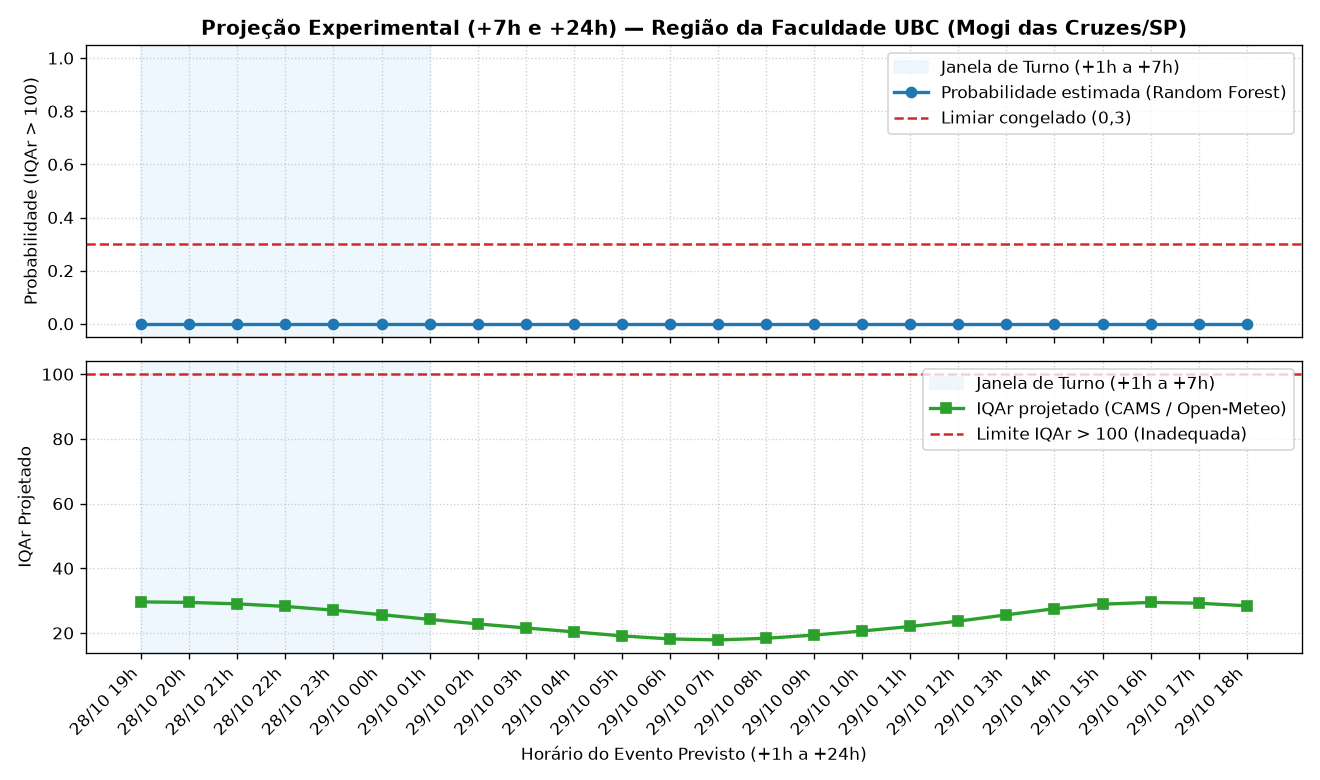

In [5]:
import matplotlib.pyplot as plt

display(projecao_24h)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
x = range(1, len(projecao_24h) + 1)
labels = [pd.Timestamp(t).strftime('%d/%m %Hh') for t in projecao_24h['horário do evento previsto']]

ax1.axvspan(1, 7, color='#e8f4fd', alpha=0.7, label='Janela de Turno (+1h a +7h)')
ax1.plot(x, projecao_24h['probabilidade estimada de IQAr > 100'], marker='o', color='#1f77b4', linewidth=2, label='Probabilidade estimada (Random Forest)')
ax1.axhline(limiar, color='#d62728', linestyle='--', linewidth=1.5, label=f'Limiar congelado ({limiar})')
ax1.set_ylabel('Probabilidade (IQAr > 100)')
ax1.set_ylim(-0.05, 1.05)
ax1.set_title('Projeção Experimental (+7h e +24h) — Região da Faculdade UBC (Mogi das Cruzes/SP)', fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

ax2.axvspan(1, 7, color='#e8f4fd', alpha=0.7, label='Janela de Turno (+1h a +7h)')
ax2.plot(x, projecao_24h['iqar projetado (CAMS)'], marker='s', color='#2ca02c', linewidth=2, label='IQAr projetado (CAMS / Open-Meteo)')
ax2.axhline(100.0, color='#d62728', linestyle='--', linewidth=1.5, label='Limite IQAr > 100 (Inadequada)')
ax2.set_ylabel('IQAr Projetado')
ax2.set_xlabel('Horário do Evento Previsto (+1h a +24h)')
ax2.set_xticks(list(x))
ax2.set_xticklabels(labels, rotation=45, ha='right')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')

fig.tight_layout()
plt.show()

## Como repetir e Interfaces Complementares do ArPrev

Para uma nova previsão, execute novamente o notebook 01 (atualiza os dados) e este notebook.

### Alternativas de Execução:

1. **Terminal / Script Operacional:**
   ```powershell
   .\.venv\Scripts\python.exe -m src.aplicacao.Prever_Proxima_Hora
   ```

2. **Dashboard Interativo Streamlit:**
   ```powershell
   .\.venv\Scripts\streamlit.exe run streamlit_app.py
   ```

3. **Artigo Técnico Web (GitHub Pages):**
   Consulte [`docs/index.html`](../docs/index.html) para o estudo aprofundado e comparativo entre Árvore de Decisão CART, Random Forest e XGBoost.

4. **Notebook Comparativo de Árvores:**
   Consulte [`04_Comparativo_Arvores_Decisao_RF_XGBoost.ipynb`](04_Comparativo_Arvores_Decisao_RF_XGBoost.ipynb) para analisar os experimentos de modelagem e latência.